<a href="https://colab.research.google.com/github/me234jl/COMM5780/blob/main/Scraping_Web_Pages_with_Python_and_BeautifulSoup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Google CoLab**

This is a Google CoLab workbook. CoLab is a cloud scripting space that gives you access to an environment for programming that is already setup and which uses cloud computing hardware and resources. It is free to use with a Google account.

You can program in Python here without installing anything; most major libraries are installed. You can import and export data too, so it is a nice place to start learning about the tools available.

CoLab workbooks can be used to allow multiple authors to collaboratively create documents and programs. I have used GitHub (a seperate repository and version control system) to store this workbook and as a result, when you access this workbook you will have your own copy to work on. Your edits won't affect the master copy and your work won't be affected by other students. You can save the workbook to your own Google or Github account whenever you want to.

**Scraping content from a web page using Python**

This workbook outlines a method of web scraping using python code. It attempts to scrape content from a particular web page on (in this example bbc.co.uk/iplayer) but can be adapted to use on other websites.

Web scraping is the process of finding specific types of content on a web page, isolating pieces of content using the HTML code that is used to present that category in the browser, and copying the specific content to another place, such as a spreadsheet or a database.

Scraping can be used to collect data in order to answer research questions. For example, "What are the most common words in TV programme titles and descriptions". Different research questions require different content to be scraped. Building your own scraper can allow you to harvest the bespoke data that you need for your research project.

On BBC iPlayer numerous TV programmes are displayed, with titles and descriptions - here we will attempt to scrape these data elements.

*The workshop handout for this week details the process of isolating the content using the HTML code that surrounds it, and shows you how to build the scraper outside of Google CoLab.*


First, we need to identify the HTML that marks up the post titles. By using the code inspector in Chrome we can identify the code around each bit of content. We can see that the programmes are held in a list with each list item identified with a CSS class:
```
<li class="carrousel__item ... >
```
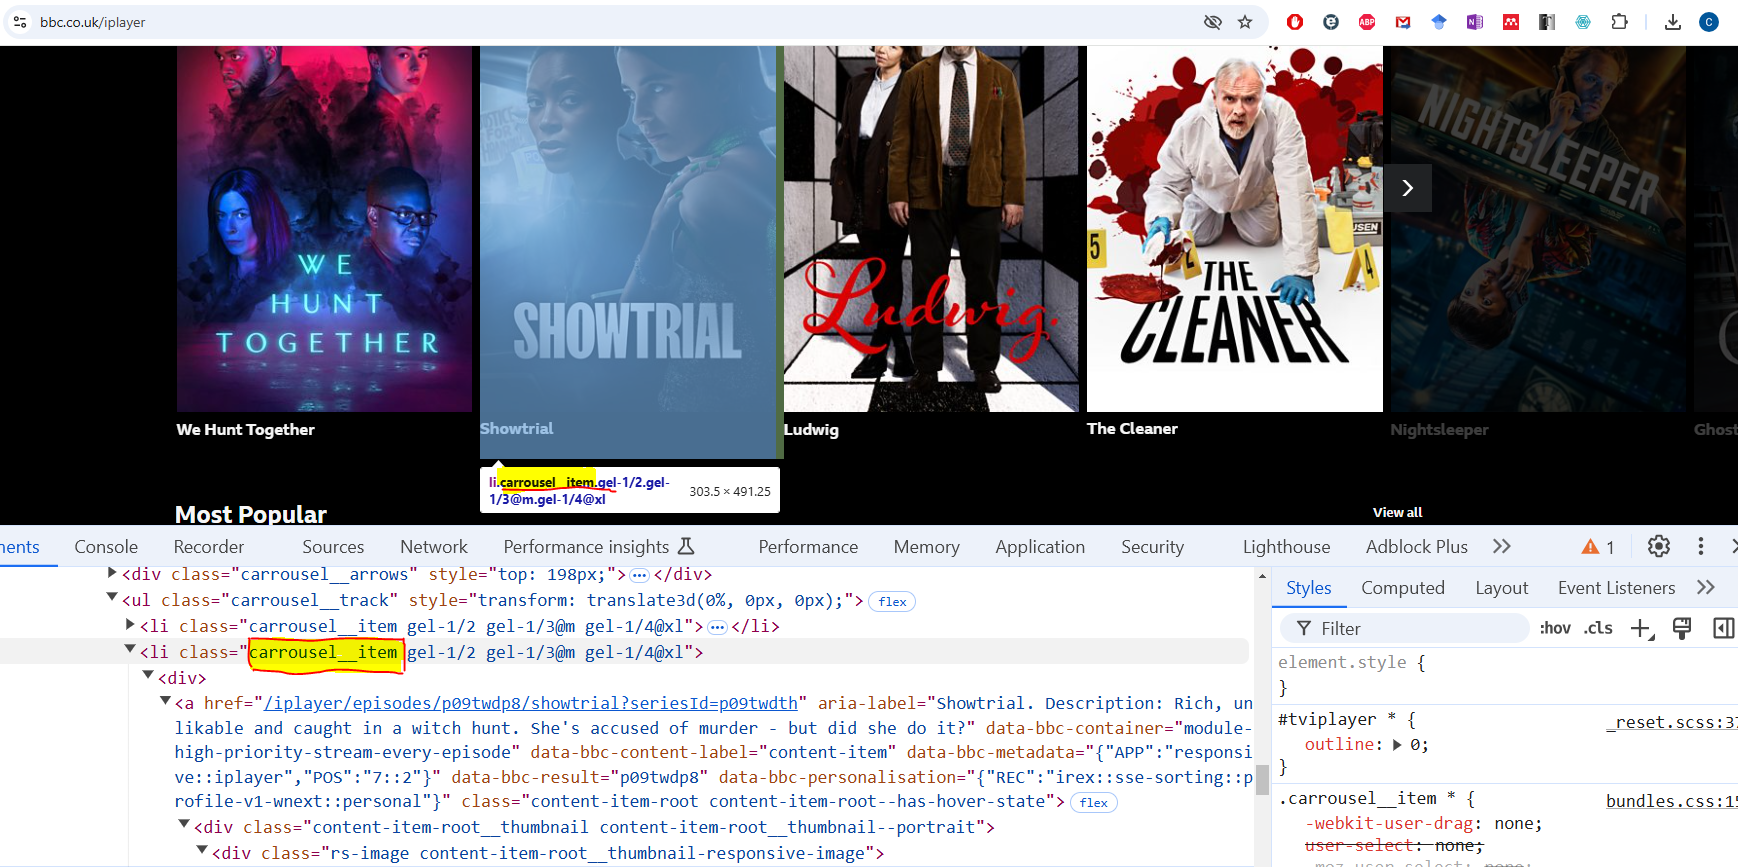



Within this carrousel element are other elements - an anchor tag and a div - that contain information about the programme (though in the anchor tag, the text description is held in an aria attribute):

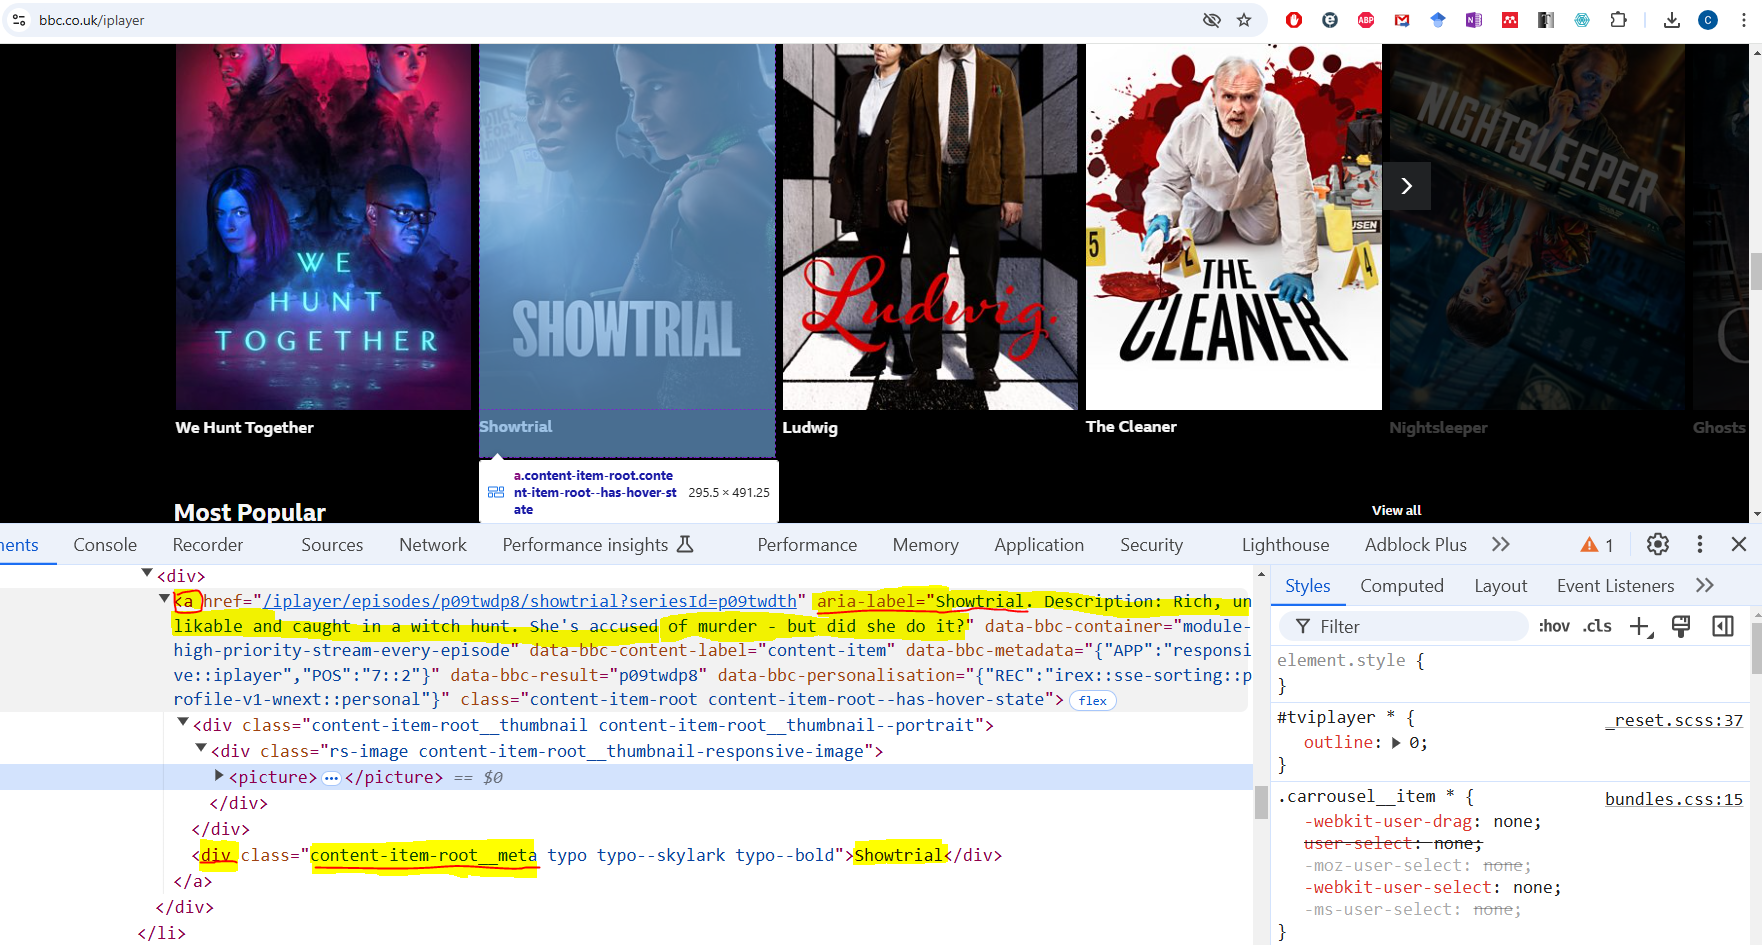

We can use those HTML identifiers to scrape the content that we want - titles and descriptions - using the following python code:

**Script for scraping BBC iPlayer:**

In [31]:
from bs4 import BeautifulSoup
import csv
import requests #added to deal with character encoding

titles=[] #Car name
descriptions=[] #Description
carcount=0
writecount = 0

url = "https://webscraper.io/test-sites/pagination"

#new section to respond to character encoding - Use requests with headers
headers = {
    'User-Agent': 'Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:52.0) Gecko/20100101 Firefox/52.0'
}
response = requests.get(url, headers=headers)
# Set character encoding explicitly
response.encoding = response.apparent_encoding  # or 'utf-8'
# Use BeautifulSoup with lxml parser for better handling
soup = BeautifulSoup(response.text, "lxml")

##SCRAPING TITLES AND ARIA DESCRIPTIONS IN iPLAYER
for post in soup.find_all('h3'):
  titles.append(post.text.strip())
  description=post.find_next('p')
  descriptions.append(description.text.strip())
  carcount+=1

print(len(titles))
print(titles)

6
['Mercedes-Benz W123 280E 1955', 'BMW E24 635CSi 1954', 'Jaguar XJ6 1983', 'Nissan 300ZX Z31 1966', 'Ferrari F40 1984', 'Mercedes-Benz W123 280E 1972']


# New section

In [30]:
#in Python you use the word 'print' to output a variable to the console
print(carcount)

6


In [32]:
print(titles)

['Mercedes-Benz W123 280E 1955', 'BMW E24 635CSi 1954', 'Jaguar XJ6 1983', 'Nissan 300ZX Z31 1966', 'Ferrari F40 1984', 'Mercedes-Benz W123 280E 1972']


In [33]:
print(descriptions)

['Uncompromising Stuttgart saloon', 'Shark-nose grand tourer', 'Silky British luxury saloon', 'Angular Japanese sports coupe', 'Raw Prancing Horse icon', 'Early W123, driver condition']


**Exporting the data**

There are lots of ways to export data from colab, using your Google drive account or creating files that can be downloaded.

One example is shown below. First, create a new file in the Files menu in the top left of the colab workbook if there is not already one there.
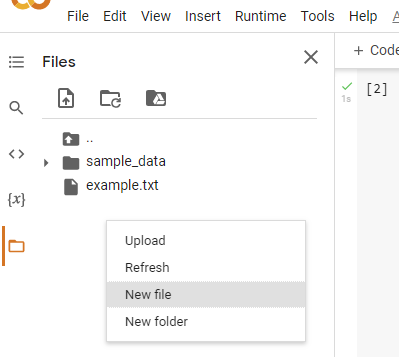

*In the code below, the filename must exactly match the name of the file that you have created.*

*The path must also be correct - folder management is key here!*

To write the data to that file:

In [ ]:
#reset writecount variable, just in case:
writecount = 0

# Write line to file
# the second argument in the open() function - 'a' or 'w'- means 'append' (add data to the end of the file) or 'write' replace the data with new data
# the '\n' character is an 'end line' character and will mean that any more content is written on a new line

## WRITING FROM BBC iPLAYER
with open('example.txt', 'w') as writefile:
    for title in titles:
        writefile.write(title + ": " + descriptions[writecount] + "\n")
        writecount += 1



You can also read from this file:

In [ ]:
# Read file

with open('example.txt', 'r') as writefile:
    print(writefile.read())

Time: Time. Category: Crime Drama. Description: Inside these prison walls, everyone carries something. What matters is what they do next.
Blue Lights: Blue Lights. Category: Crime Drama. Description: A new threat, an old murder and buried secrets push the officers into dangerous territory.
Storyville: Storyville. Category: Documentary Film. Duration: 1h 35m. Description: Black Is Beautiful: The Kwame Brathwaite Story. How his iconic art changed black identity.
Thank You Sir Kev: Thank You Sir Kev. Category: Sport. Duration: 29 mins. Description: A real-life superhero. Prince William leads tributes to MND fundraiser Sir Kevin Sinfield.
Murder in Belfast: Sisters Seeking Justice: Murder in Belfast: Sisters Seeking Justice. Category: Documentary. Description: A stabbing on a street. Scared witnesses. Who will tell Robert’s family who killed him?
Escaping Idi Amin: Escaping Idi Amin. Category: History. Description: Get out or face the consequences. Survivors tell the tale of a dictator’s c

**Downloading the data**

You can download this file from the menu in colab by right-clicking and choosing 'download from the context menu.

**Working with CSV files and spreadsheets**

You can also use built-in libraries in python and colab (such as csv or pandas) to write data to spreadsheets as well as text files:

In [ ]:
#reset writecount variable, just in case:
writecount = 0

##SCRAPING BBC iPLAYER - with descriptions
with open('bbcprogs.csv', 'w', newline='') as csv_file:
    writer = csv.writer(csv_file)
    for title in titles:
        writer.writerow([title, descriptions[writecount]])
        writecount+=1

In [ ]:
#rows written:
print(writecount)

106


In [ ]:
#reading the csv file:
with open('bbcprogs.csv', 'r') as csv_file:
    reader = csv.reader(csv_file)
    for row in reader:
      print(row)


['Time', 'Time. Category: Crime Drama. Description: Inside these prison walls, everyone carries something. What matters is what they do next.']
['Blue Lights', 'Blue Lights. Category: Crime Drama. Description: A new threat, an old murder and buried secrets push the officers into dangerous territory.']
['Storyville', 'Storyville. Category: Documentary Film. Duration: 1h 35m. Description: Black Is Beautiful: The Kwame Brathwaite Story. How his iconic art changed black identity.']
['Thank You Sir Kev', 'Thank You Sir Kev. Category: Sport. Duration: 29 mins. Description: A real-life superhero. Prince William leads tributes to MND fundraiser Sir Kevin Sinfield.']
['Murder in Belfast: Sisters Seeking Justice', 'Murder in Belfast: Sisters Seeking Justice. Category: Documentary. Description: A stabbing on a street. Scared witnesses. Who will tell Robert’s family who killed him?']
['Escaping Idi Amin', 'Escaping Idi Amin. Category: History. Description: Get out or face the consequences. Survivo

You can downlaod this CSV file for use elsewhere, save it to your Google drive, or process it further with data libraries and visualisation tools within python.

One such data library is Pandas. See this tutorial for more details: https://colab.research.google.com/notebooks/mlcc/intro_to_pandas.ipynb

One graphing library for charts is matplotlib: https://colab.research.google.com/notebooks/charts.ipynb

**The challenge for this week**

*Scrape different data from a different website!*

Think about research questions that you could answer using scraped data from online digital platforms. Which websites would you need to access? How is the data marked up?

Identify the markers in the HTML code that identify the content types that you want toscrape and modify the code above to scrape a web page, write the data to file and download it to your local machine.

You can add a code section at the bottom of this workbook to hold your new code (so the existing code above remains unchanged).